In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

#  REGRESSION DATASET: Predicting Logistics Shipping Cost
np.random.seed(42)  # Ensures reproducible results
n_samples = 30

distance_km = np.random.randint(150, 2200, size=n_samples)
weight_kg = np.round(np.random.uniform(2.0, 30.0, size=n_samples), 1)

shipping_cost = np.round(100 + (0.85 * distance_km) + (15 * weight_kg) + np.random.normal(0, 35, n_samples), 2)

df_logistics = pd.DataFrame({
    "distance_km": distance_km,
    "weight_kg": weight_kg,
    "shipping_cost": shipping_cost
})

df_logistics.head()

,distance_km,weight_kg,shipping_cost
0,1010,6.8,1087.58
1,1444,3.8,1365.57
2,1280,28.6,1569.87
3,1245,29.0,1562.43
4,1788,24.6,1949.23


In [2]:
#  TRAIN-TEST SPLIT & MODEL TRAINING (LINEAR REGRESSION)
X = df_logistics[["distance_km", "weight_kg"]]  
y = df_logistics["shipping_cost"]               

# contain 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train the Linear Regression model
reg_model = LinearRegression()
reg_model.fit(X_train, y_train)

print("✅ Linear Regression Model Trained!")
print(f"Intercept (Base Cost): ₹{reg_model.intercept_:.2f}")
print(f"Coefficients (Per km, Per kg): {reg_model.coef_.round(2)}")

✅ Linear Regression Model Trained!
Intercept (Base Cost): ₹140.10
Coefficients (Per km, Per kg): [ 0.84 13.79]


In [3]:
#  EVALUATE REGRESSION MODEL & MAKE PREDICTIONS
y_pred = reg_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): ₹{mae:.2f}")
print(f"R² Score (Accuracy of Fit): {r2:.4f}")

# Compare Actual vs Predicted 
comparison = pd.DataFrame({"Actual Cost (₹)": y_test.values, "Predicted Cost (₹)": y_pred.round(2)})
print("\n--- Test Set Predictions ---")
print(comparison)

# Predict cost for a brand-new shipment (850 km, 12.5 kg)
new_shipment = pd.DataFrame({"distance_km": [850], "weight_kg": [12.5]})
predicted_price = reg_model.predict(new_shipment)[0]
print(f"\n📦 Predicted Cost for 850 km, 12.5 kg shipment: ₹{predicted_price:.2f}")

Mean Absolute Error (MAE): ₹31.84
R² Score (Accuracy of Fit): 0.9965

--- Test Set Predictions ---
   Actual Cost (₹)  Predicted Cost (₹)
0          1321.74             1373.26
1          1380.04             1405.72
2          2070.95             2037.35
3           473.41              521.94
4          1733.00             1705.12
5           445.42              449.23

📦 Predicted Cost for 850 km, 12.5 kg shipment: ₹1024.87


In [4]:
# CLASSIFICATION MODEL: IRIS FLOWER SPECIES
from sklearn.datasets import load_iris
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load the built-in Iris dataset
iris = load_iris()
X_iris = pd.DataFrame(iris.data, columns=iris.feature_names)
y_iris = iris.target

#  80% train, 20% test
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_iris, y_iris, test_size=0.2, random_state=42
)

# Train a Random Forest Classifier
clf_model = RandomForestClassifier(n_estimators=100, random_state=42)
clf_model.fit(X_train_c, y_train_c)

# Predict on test data
y_pred_c = clf_model.predict(X_test_c)

# Evaluate Classification Performance
accuracy = accuracy_score(y_test_c, y_pred_c)
print(f"✅ Iris Classification Accuracy: {accuracy * 100:.2f}%\n")
print("--- Classification Report ---")
print(classification_report(y_test_c, y_pred_c, target_names=iris.target_names))

✅ Iris Classification Accuracy: 100.00%

--- Classification Report ---
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



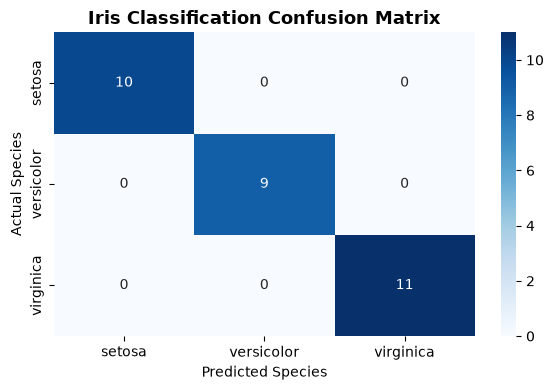

In [5]:
# CONFUSION MATRIX VISUALIZATION
cm = confusion_matrix(y_test_c, y_pred_c)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)
plt.title("Iris Classification Confusion Matrix", fontsize=13, fontweight="bold")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.tight_layout()
plt.show()